# Chicago Taxi Trips — week of 11–17 September 2023

A descriptive summary of one week of reported taxi trips: when people ride, where trips start, how they pay and tip, and which companies carry the trips.

**Summary placeholder — replaced at the end of the notebook build.**

---
## 1. Setup and data loading
**Conventions used throughout**
- Every figure is *reported trips*, not total market volume (the City notes not all trips are reported).
- "Revenue" means `trip_total` as reported. It includes tips, tolls and extras, so it is what the rider was charged, not what the company or driver kept.
- Timestamps are local time, rounded to 15 minutes. The brief and `dataset.md` don't state a time zone, so I assume Chicago local time. Durations use `trip_seconds`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

FIG_DIR = Path("figures/analysis")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: white surface, thin marks, recessive grid, no dual axes.
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#9a9a96", "#0b0b0b"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})

In [2]:
raw = pd.read_csv("trips.csv", dtype={"trip_id": "string", "taxi_id": "string"})
raw["start"] = pd.to_datetime(raw["trip_start_timestamp"])
raw["end"] = pd.to_datetime(raw["trip_end_timestamp"])

print("Rows, columns:", raw.shape, "(brief says 135,768 rows)")
print("Start range  :", raw["start"].min(), "->", raw["start"].max())
print("Duplicate trip_id:", raw["trip_id"].duplicated().sum(), "| fully duplicated rows:", raw.drop(columns=["start", "end"]).duplicated().sum())
print("Trips per calendar date:")
print(raw["start"].dt.date.value_counts().sort_index().to_string())

Rows, columns: (135768, 25) (brief says 135,768 rows)
Start range  : 2023-09-11 00:00:00 -> 2023-09-17 23:45:00
Duplicate trip_id: 0 | fully duplicated rows: 0
Trips per calendar date:
start
2023-09-11    22190
2023-09-12    22040
2023-09-13    22694
2023-09-14    22531
2023-09-15    20226
2023-09-16    12719
2023-09-17    13368


In [3]:
miss = raw.drop(columns=["start", "end"]).isna().sum()
miss = pd.DataFrame({"missing": miss, "pct": miss / len(raw) * 100})
print(miss[miss.missing > 0].to_string())

                            missing   pct
trip_end_timestamp                1  0.00
trip_seconds                     33  0.02
pickup_census_tract           71404 52.59
dropoff_census_tract          73842 54.39
pickup_community_area          3815  2.81
dropoff_community_area        13794 10.16
fare                            324  0.24
tips                            324  0.24
tolls                           324  0.24
extras                          324  0.24
trip_total                      324  0.24
pickup_centroid_latitude       3775  2.78
pickup_centroid_longitude      3775  2.78
pickup_centroid_location       3775  2.78
dropoff_centroid_latitude     12872  9.48
dropoff_centroid_longitude    12872  9.48
dropoff_centroid_location     12872  9.48


---
## 2. Data quality checks and cleaning
First I measure every issue on the raw data; the treatment decisions come after, in a numbered list with row counts.

In [4]:
d = raw.copy()
parts = d["fare"] + d["tips"] + d["tolls"] + d["extras"]
d["gap"] = (d["trip_total"] - parts).round(2)           # trip_total minus the sum of its parts
d["mph"] = d["trip_miles"] / (d["trip_seconds"] / 3600)  # implied speed

checks = {
    "trip_miles == 0": d["trip_miles"].eq(0),
    "trip_miles > 100": d["trip_miles"].gt(100),
    "trip_seconds == 0": d["trip_seconds"].eq(0),
    "trip_seconds > 4 hours": d["trip_seconds"].gt(4 * 3600),
    "trip_seconds missing": d["trip_seconds"].isna(),
    "miles == 0 and seconds == 0": d["trip_miles"].eq(0) & d["trip_seconds"].eq(0),
    "implied speed > 80 mph": d["mph"].gt(80),
    "money fields missing (fare/tips/tolls/extras/total)": d["trip_total"].isna(),
    "fare == 0": d["fare"].eq(0),
    "trip_total == 0": d["trip_total"].eq(0),
    "trip_total > $200": d["trip_total"].gt(200),
    "trip_total > $500": d["trip_total"].gt(500),
    "tolls > $100": d["tolls"].gt(100),
    "extras > $100": d["extras"].gt(100),
    "tips > fare": d["tips"].gt(d["fare"]),
    "trip_total != sum of parts (any gap)": d["gap"].ne(0) & d["gap"].notna(),
}
chk = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in checks.items()}})
chk["pct_of_rows"] = chk["rows"] / len(d) * 100
print(chk.to_string())

                                                      rows  pct_of_rows
trip_miles == 0                                      13993        10.31
trip_miles > 100                                        11         0.01
trip_seconds == 0                                     2731         2.01
trip_seconds > 4 hours                                 121         0.09
trip_seconds missing                                    33         0.02
miles == 0 and seconds == 0                           2637         1.94
implied speed > 80 mph                                 228         0.17
money fields missing (fare/tips/tolls/extras/total)    324         0.24
fare == 0                                              135         0.10
trip_total == 0                                        134         0.10
trip_total > $200                                      109         0.08
trip_total > $500                                        8         0.01
tolls > $100                                             3      

In [5]:
print("Gap = trip_total minus (fare + tips + tolls + extras), rows where gap != 0:")
g = d.loc[d["gap"].ne(0) & d["gap"].notna(), "gap"].value_counts().sort_index()
print(g.to_string())
print("\nNegative gaps (total smaller than parts):", int((d["gap"] < 0).sum()))
print("\nShare of trips with a +$0.50 gap, by payment_type:")
print(d.assign(g50=d["gap"].eq(0.5)).groupby("payment_type")["g50"].agg(["sum", "mean"]).rename(columns={"sum": "trips", "mean": "share"}).to_string())

Gap = trip_total minus (fare + tips + tolls + extras), rows where gap != 0:
gap
0.50    46522
1.00      109
1.50        4
1.95        5
2.00        2
2.50      751
3.00      804

Negative gaps (total smaller than parts): 0

Share of trips with a +$0.50 gap, by payment_type:
              trips  share
payment_type              
Cash              3   0.00
Credit Card   42409   0.70
Dispute           0   0.00
Mobile         4110   0.22
No Charge         0   0.00
Prcard            0   0.00
Unknown           0   0.00


In [6]:
print("Trips with only the $3.25 base fare, zero miles, but a large extra or tip (meter not run?):")
sus = d[(d["trip_miles"] == 0) & (d["fare"] <= 3.5) & ((d["extras"] >= 20) | (d["tips"] >= 5))]
print(len(sus), "rows; median extras", sus["extras"].median(), "| median tips", sus["tips"].median(), "| median total", sus["trip_total"].median())
print("\nLargest 8 trip_total values:")
print(d.nlargest(8, "trip_total")[["trip_miles", "trip_seconds", "fare", "tips", "tolls", "extras", "trip_total", "payment_type"]].to_string())

Trips with only the $3.25 base fare, zero miles, but a large extra or tip (meter not run?):
597 rows; median extras 44.0 | median tips 6.22 | median total 53.25

Largest 8 trip_total values:
        trip_miles  trip_seconds   fare  tips    tolls   extras  trip_total payment_type
124235        0.10      1,080.00  11.25  0.00 4,444.44 4,445.44    8,901.13         Cash
25636         0.00          0.00   3.25  0.00 4,444.44 4,444.44    8,892.13         Cash
35524         1.30        420.00   6.75  0.00 4,111.10     0.44    4,118.29         Cash
127990       37.45           NaN 911.00  0.00     0.00     0.00      911.00         Cash
31648         0.00          3.00 900.00  0.00     0.00     0.00      900.00         Cash
99632         0.00         60.00 758.00  0.00     0.00     0.00      758.00    No Charge
30785         0.00          0.00 550.00  0.00     0.00     0.00      550.00  Credit Card
51799         0.00          0.00 550.00  0.00     0.00     0.00      550.00         Cash


In [7]:
# Exclusion rules (each a boolean mask on the raw rows)
secs = d["trip_seconds"]
fare_per_min = np.where(secs.eq(0), np.inf, d["fare"] / (secs / 60))      # NaN seconds -> NaN -> not flagged
r3_parts = {
    "total > $500": d["trip_total"].gt(500),
    "tolls > $100": d["tolls"].gt(100),
    "fare >= $100 and over $5 per minute": d["fare"].ge(100) & pd.Series(fare_per_min, index=d.index).gt(5),
}
rules = {
    "R1": d["trip_total"].isna(),
    "R2": d["trip_total"].eq(0),
    "R3": pd.concat(r3_parts, axis=1).any(axis=1),
}
ledger, dropped_so_far = [], pd.Series(False, index=d.index)
for name, m in rules.items():
    ledger.append({"rule": name, "standalone_rows": int(m.sum()),
                   "additional_rows_removed": int((m & ~dropped_so_far).sum())})
    dropped_so_far |= m
ledger = pd.DataFrame(ledger).set_index("rule")
ledger.loc["Total"] = ledger.sum()
print(ledger.to_string())
print(f"\nRows before: {len(d):,} | removed: {int(dropped_so_far.sum()):,} ({dropped_so_far.mean()*100:.2f}%) | rows kept: {int((~dropped_so_far).sum()):,}")
print("\nR3 sub-conditions (rows, overlapping):", {k: int(v.sum()) for k, v in r3_parts.items()})
print("R3 rows by payment type:", d.loc[rules["R3"], "payment_type"].value_counts().to_dict())
print("R3 median miles / seconds / fare:", d.loc[rules["R3"], ["trip_miles", "trip_seconds", "fare"]].median().round(2).to_dict())

       standalone_rows  additional_rows_removed
rule                                           
R1                 324                      324
R2                 134                      134
R3                 156                      156
Total              614                      614

Rows before: 135,768 | removed: 614 (0.45%) | rows kept: 135,154

R3 sub-conditions (rows, overlapping): {'total > $500': 8, 'tolls > $100': 3, 'fare >= $100 and over $5 per minute': 152}
R3 rows by payment type: {'Credit Card': 130, 'Cash': 24, 'No Charge': 2}
R3 median miles / seconds / fare: {'trip_miles': 0.0, 'trip_seconds': 7.0, 'fare': 147.0}


In [8]:
# Show that R3 leaves plausible long/slow trips alone: highest remaining fares
keep_mask = ~dropped_so_far
print("Ten highest remaining fares:")
print(d[keep_mask].nlargest(10, "fare")[["trip_miles", "trip_seconds", "fare", "tips", "tolls", "extras", "trip_total", "payment_type"]].to_string())

Ten highest remaining fares:
        trip_miles  trip_seconds   fare  tips  tolls  extras  trip_total payment_type
52838       195.66     18,154.00 471.50  0.00   0.00    9.00      483.00  Credit Card
5186        194.81     15,011.00 445.50  0.00   0.00   24.50      472.50  Credit Card
7673        105.76     37,468.00 378.75  0.00   0.00    0.00      378.75         Cash
108611      147.88      8,596.00 338.00  0.00   0.00   62.00      402.00  Credit Card
21057       127.44     10,597.00 293.00  0.00   0.00    5.00      298.00         Cash
70658       115.27      6,467.00 264.00 75.62   6.00   31.00      378.12  Credit Card
39536        75.73      5,479.00 250.00  0.00   0.00    0.00      250.00         Cash
109308       57.86      4,848.00 242.00  0.00   0.00    0.00      243.50  Credit Card
85325       101.26      8,599.00 238.75  0.00   0.00  143.00      383.25  Credit Card
120690       41.40     29,066.00 231.50  0.00   0.00    4.00      235.50         Cash


In [9]:
# Standardise company names: two companies appear under two spellings each.
print(sorted(d["company"].unique()))
company_map = {
    "Taxicab Insurance Agency, LLC": "Taxicab Insurance Agency Llc",
    "Choice Taxi Association Inc": "Choice Taxi Association",
}
d["company_std"] = d["company"].replace(company_map)
print("\nRows renamed:", int(d["company"].isin(company_map).sum()), "| distinct companies before/after:", d["company"].nunique(), "/", d["company_std"].nunique())

['2733 - 74600 Benny Jona', '312 Medallion Management Corp', '3556 - 36214 RC Andrews Cab', '4053 - 40193 Adwar H. Nikola', '4623 - 27290 Jay Kim', '4787 - 56058 Reny Cab Co', '5 Star Taxi', '5167 - 71969 5167 Taxi Inc', '6574 - Babylon Express Inc.', 'Blue Ribbon Taxi Association', 'Chicago City Taxi Association', 'Chicago Independents', 'Chicago Taxicab', 'Choice Taxi Association', 'Choice Taxi Association Inc', 'City Service', 'Flash Cab', 'Globe Taxi', 'Koam Taxi Association', 'Medallion Leasin', 'Metro Jet Taxi A.', 'Patriot Taxi Dba Peace Taxi Associat', 'Petani Cab Corp', 'Setare Inc', 'Star North Taxi Management Llc', 'Sun Taxi', 'Taxi Affiliation Services', 'Taxi Affiliation Services Llc - Yell', 'Taxicab Insurance Agency Llc', 'Taxicab Insurance Agency, LLC', 'Top Cab', 'U Taxicab']

Rows renamed: 3443 | distinct companies before/after: 32 / 30


In [10]:
trips = d.loc[~dropped_so_far].copy()
trips["company"] = trips["company_std"]
trips["day"] = pd.Categorical(trips["start"].dt.day_name(),
    categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
trips["hour"] = trips["start"].dt.hour
trips["is_weekend"] = trips["start"].dt.day_of_week >= 5
trips["pickup_area"] = trips["pickup_community_area"].astype("Int64")

print("Analysis frame:", trips.shape[0], "trips (from", len(raw), "raw)")
kept_flags = {
    "trip_miles == 0": trips["trip_miles"].eq(0),
    "trip_miles > 100": trips["trip_miles"].gt(100),
    "trip_seconds == 0": trips["trip_seconds"].eq(0),
    "trip_seconds missing": trips["trip_seconds"].isna(),
    "trip_seconds > 4 hours": trips["trip_seconds"].gt(4 * 3600),
    "implied speed > 80 mph": trips["mph"].gt(80),
    "tips > fare": trips["tips"].gt(trips["fare"]),
    "trip_total > sum of parts": trips["gap"].gt(0),
}
kf = pd.DataFrame({"rows_kept_but_flagged": {k: int(v.sum()) for k, v in kept_flags.items()}})
kf["pct_of_analysis_rows"] = kf["rows_kept_but_flagged"] / len(trips) * 100
print(kf.to_string())
any_flag = pd.concat([kept_flags[k] for k in list(kept_flags)[:6]], axis=1).any(axis=1)
print(f"\nTrips with at least one miles/duration flag: {int(any_flag.sum()):,} ({any_flag.mean()*100:.1f}%)")
print("Checks: weekdays covered =", sorted(trips['day'].unique().tolist()) == sorted(trips['day'].cat.categories.tolist()),
      "| money NaNs =", int(trips[['fare','tips','tolls','extras','trip_total']].isna().sum().sum()))

Analysis frame: 135154 trips (from 135768 raw)
                           rows_kept_but_flagged  pct_of_analysis_rows
trip_miles == 0                            13750                 10.17
trip_miles > 100                              11                  0.01
trip_seconds == 0                           2645                  1.96
trip_seconds missing                          23                  0.02
trip_seconds > 4 hours                       119                  0.09
implied speed > 80 mph                       225                  0.17
tips > fare                                  864                  0.64
trip_total > sum of parts                  48089                 35.58

Trips with at least one miles/duration flag: 14,100 (10.4%)
Checks: weekdays covered = True | money NaNs = 0


### Cleaning decisions and assumptions
Every decision is applied once, here, and every table below uses the same cleaned frame (`trips`).

**Rows removed (614 of 135,768, 0.45%)**
1. **R1 – money fields missing: 324 rows.** `fare`, `tips`, `tolls`, `extras` and `trip_total` are all blank together (323 are cash trips), so revenue can't be computed. Removed from every table, including trip counts, so counts and revenue describe the same trips.
2. **R2 – `trip_total` equals $0: 134 rows.** Almost all cash, with a median duration of about a minute. These look like aborted or unrecorded fares, not paid trips. Removed.
3. **R3 – implausible amounts: 156 rows.** Any of: `trip_total` over $500 (8 rows, including three with $4,100–$4,445 tolls/extras on trips under 2 miles); `tolls` over $100 (3 rows); or a `fare` of at least $100 accruing faster than $5 per minute (152 rows; median 0 miles, 7 seconds, $147). Long trips with a high fare over a plausible duration (for example 195 miles for $471) are kept.

**Rows kept, with a flag (not removed)**
4. **Zero or extreme miles/durations** (counts in the table above). No question in the brief uses `trip_miles` or `trip_seconds`, and 10% of trips report 0 miles, so dropping them would understate demand. They stay in. In section 7 I re-run the headline figures after removing every flagged row to show the conclusions don't depend on this choice.
5. **`trip_total` above the sum of its parts: 35% of trips, never below.** 46,522 trips have a gap of exactly $0.50, almost all Credit Card or Mobile (3 Cash trips, no Prcard), so it looks like an unitemised card fee. A further ~1,700 trips have gaps of $1–$3. I assume `trip_total` is what the rider was charged and use it as reported for revenue. Because the gap is one-directional, it isn't evidence of corrupted rows.
6. **`tips` greater than `fare` (864 rows).** About 60% of them report 0 miles and 76% have a fare of $5 or less (typically the $3.25 base fare), so the meter was probably not run. Kept in revenue; handled explicitly in the tipping section.

**Other assumptions**
7. **Company names:** "Taxicab Insurance Agency, LLC" is merged into "Taxicab Insurance Agency Llc" (2,379 rows), and "Choice Taxi Association Inc" into "Choice Taxi Association" (1,064 rows). Without the first merge that company would rank 4th instead of 3rd. "Taxi Affiliation Services Llc - Yell" (75 rows) is probably Yellow Cab under the same group as "Taxi Affiliation Services", but I can't verify that and it doesn't affect the top 10, so I left it separate. No other names were changed.
8. **Geography:** community areas only, shown as the numeric code from the data. Names would need outside data, which is out of scope. Census tracts are not used (53% blank).
9. **Day and hour** come from `trip_start_timestamp` (15-minute rounded, assumed local time). Hour 0 is midnight to 12:59am, and so on. The week runs Monday to Sunday, so every day is complete.
10. **Missing `trip_seconds` (33 rows) and `trip_end_timestamp` (1 row)** are left as they are, since neither is used in any table.

---
## 3. Q1 — When is demand highest?
Trips counted by day of week and by hour of trip start (cleaned reported trips).

In [11]:
by_day = trips.groupby("day", observed=True).agg(trips=("trip_id", "size"), revenue=("trip_total", "sum"))
by_day["share_%"] = by_day["trips"] / by_day["trips"].sum() * 100
print(by_day.round(1).to_string())
print(f"\nBusiest day: {by_day['trips'].idxmax()} ({by_day['trips'].max():,}) | quietest day: {by_day['trips'].idxmin()} ({by_day['trips'].min():,})")
wd, we = trips[~trips.is_weekend], trips[trips.is_weekend]
print(f"Weekday (Mon-Fri) average per day: {len(wd)/5:,.0f} | Weekend (Sat-Sun) average per day: {len(we)/2:,.0f} | ratio {len(we)/2/(len(wd)/5):.2f}")
print(f"Mon-Thu average per day: {trips[trips.day.isin(['Monday','Tuesday','Wednesday','Thursday'])].shape[0]/4:,.0f} vs Friday: {by_day.loc['Friday','trips']:,}")

           trips    revenue  share_%
day                                 
Monday     22080 659,563.60    16.30
Tuesday    21947 609,910.00    16.20
Wednesday  22604 643,657.60    16.70
Thursday   22443 675,065.00    16.60
Friday     20143 603,465.80    14.90
Saturday   12632 363,457.80     9.30
Sunday     13305 469,934.10     9.80

Busiest day: Wednesday (22,604) | quietest day: Saturday (12,632)


Weekday (Mon-Fri) average per day: 21,843 | Weekend (Sat-Sun) average per day: 12,968 | ratio 0.59
Mon-Thu average per day: 22,268 vs Friday: 20,143


In [12]:
hour_all = trips.groupby("hour").size().rename("trips_week")
hour_type = pd.DataFrame({
    "weekday_avg_per_day": trips[~trips.is_weekend].groupby("hour").size() / 5,
    "weekend_avg_per_day": trips[trips.is_weekend].groupby("hour").size() / 2,
}).fillna(0)
hours = pd.concat([hour_all, hour_type], axis=1)
hours["share_of_week_%"] = hours["trips_week"] / hours["trips_week"].sum() * 100
print(hours.round(1).to_string())

      trips_week  weekday_avg_per_day  weekend_avg_per_day  share_of_week_%
hour                                                                       
0           2388               332.60               362.50             1.80
1           1411               167.40               287.00             1.00
2            769                75.40               196.00             0.60
3            628                75.00               126.50             0.50
4            860               119.20               132.00             0.60
5           1352               219.40               127.50             1.00
6           2585               436.40               201.50             1.90
7           4585               812.80               260.50             3.40
8           6582             1,156.60               399.50             4.90
9           7583             1,302.40               535.50             5.60
10          7649             1,271.60               645.50             5.70
11          

In [13]:
for col in ["trips_week", "weekday_avg_per_day", "weekend_avg_per_day"]:
    s = hours[col]
    print(f"{col:22s} busiest hours: {s.nlargest(3).index.tolist()} ({s.nlargest(3).round(0).astype(int).tolist()}) | quietest hours: {s.nsmallest(3).index.tolist()} ({s.nsmallest(3).round(0).astype(int).tolist()})")
night = hours.loc[[0,1,2,3,4,5], ["weekday_avg_per_day", "weekend_avg_per_day"]].sum() / hours[["weekday_avg_per_day", "weekend_avg_per_day"]].sum() * 100
print("\nShare of a day's trips starting 00:00-05:59  ->  weekday: %.1f%% | weekend: %.1f%%" % tuple(night))
late = hours.loc[[22, 23], ["weekday_avg_per_day", "weekend_avg_per_day"]].sum() / hours[["weekday_avg_per_day", "weekend_avg_per_day"]].sum() * 100
print("Share starting 22:00-23:59 -> weekday: %.1f%% | weekend: %.1f%%" % tuple(late))

trips_week             busiest hours: [17, 15, 14] ([9462, 9422, 9245]) | quietest hours: [3, 2, 4] ([628, 769, 860])
weekday_avg_per_day    busiest hours: [17, 15, 14] ([1549, 1515, 1492]) | quietest hours: [3, 2, 4] ([75, 75, 119])
weekend_avg_per_day    busiest hours: [15, 14, 12] ([924, 892, 860]) | quietest hours: [3, 5, 4] ([126, 128, 132])

Share of a day's trips starting 00:00-05:59  ->  weekday: 4.5% | weekend: 9.5%
Share starting 22:00-23:59 -> weekday: 4.7% | weekend: 6.5%


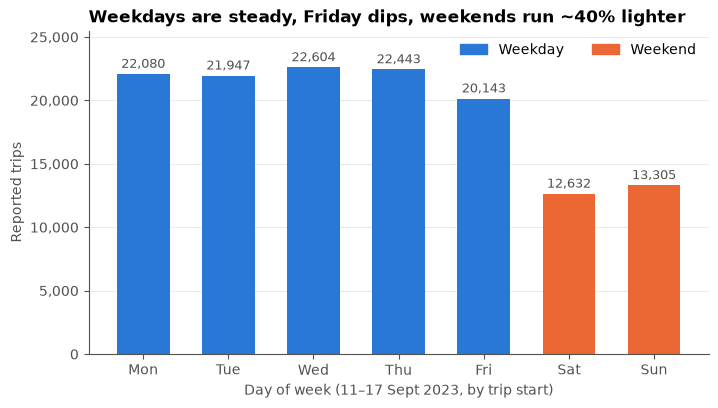

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [BLUE if not w else ORANGE for w in [False]*5 + [True]*2]
bars = ax.bar([x[:3] for x in by_day.index], by_day["trips"], color=colors, width=0.62)
for b, v in zip(bars, by_day["trips"]):
    ax.text(b.get_x() + b.get_width()/2, v + 250, f"{v:,}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_title("Weekdays are steady, Friday dips, weekends run ~40% lighter")
ax.set_xlabel("Day of week (11–17 Sept 2023, by trip start)")
ax.set_ylabel("Reported trips")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, 25500); ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Weekday"), Patch(color=ORANGE, label="Weekend")], frameon=False, loc="upper right", ncol=2)
plt.savefig(FIG_DIR / "01_trips_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

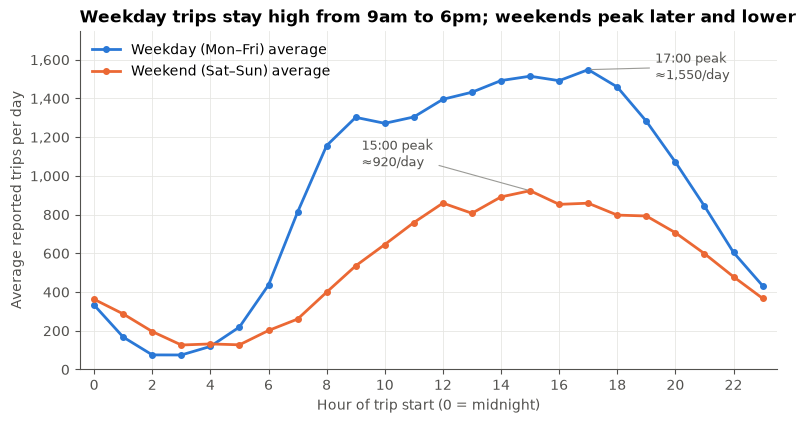

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(hours.index, hours["weekday_avg_per_day"], color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon–Fri) average")
ax.plot(hours.index, hours["weekend_avg_per_day"], color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat–Sun) average")
ax.annotate("17:00 peak\n≈1,550/day", (17, hours.loc[17, "weekday_avg_per_day"]), xytext=(19.3, 1500), fontsize=9, color="#52514e",
            arrowprops=dict(arrowstyle="-", color="#9a9a96", lw=0.8))
ax.annotate("15:00 peak\n≈920/day", (15, hours.loc[15, "weekend_avg_per_day"]), xytext=(9.2, 1050), fontsize=9, color="#52514e",
            arrowprops=dict(arrowstyle="-", color="#9a9a96", lw=0.8))
ax.set_title("Weekday trips stay high from 9am to 6pm; weekends peak later and lower")
ax.set_xlabel("Hour of trip start (0 = midnight)")
ax.set_ylabel("Average reported trips per day")
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(0, 1750)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, loc="upper left")
plt.savefig(FIG_DIR / "02_trips_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway (Q1).** Demand is highest on weekdays. Wednesday is the busiest day (22,604 reported trips) and Saturday the quietest (12,632). Monday to Thursday are almost flat at about 22,300 trips a day, Friday is about 10% lower (20,143), and the weekend averages 12,968 a day, about 41% fewer than the weekday average of 21,843.

By hour, weekday trips climb sharply between 6am and 9am and then stay between about 1,270 and 1,550 trips per hour from 9am until 7pm, with the highest hour at 5pm (about 1,550 a day). The quietest hours are 2am to 4am, with about 75 trips an hour on weekdays. Weekends build more slowly, peak at 3pm (about 920 trips a day), and have a larger late-night share: 9.5% of weekend trips start between midnight and 6am, against 4.5% on weekdays. The weekend also has more trips than weekdays between midnight and 5am.

---
## 4. Q2 — Where do trips start?
Pickup community areas are shown by their numeric code (names would need outside data, which is out of scope).

In [16]:
area = trips.groupby("pickup_area").agg(trips=("trip_id", "size"), revenue=("trip_total", "sum"))
area["trip_share_%"] = area["trips"] / len(trips) * 100
area["revenue_share_%"] = area["revenue"] / trips["trip_total"].sum() * 100
area["avg_total"] = area["revenue"] / area["trips"]
top_n = area.nlargest(10, "trips")
top_r = area.nlargest(10, "revenue")
print("TOP 10 PICKUP AREAS BY TRIP COUNT")
print(top_n.round(1).to_string())
print("\nTOP 10 PICKUP AREAS BY TOTAL trip_total")
print(top_r.round(1).to_string())
print("\nTop-10 lists differ by:", sorted(set(top_n.index) ^ set(top_r.index)), "| shared areas:", len(set(top_n.index) & set(top_r.index)))
print(f"Top 10 by trips cover {top_n['trips'].sum()/len(trips)*100:.1f}% of trips; top 10 by revenue cover {top_r['revenue'].sum()/trips['trip_total'].sum()*100:.1f}% of revenue")
print("Areas with at least one pickup:", area.shape[0])

TOP 10 PICKUP AREAS BY TRIP COUNT
             trips      revenue  trip_share_%  revenue_share_%  avg_total
pickup_area                                                              
76           31545 1,729,164.30         23.30            43.00      54.80
8            28213   516,657.20         20.90            12.80      18.30
32           22057   419,532.00         16.30            10.40      19.00
28           11247   184,606.90          8.30             4.60      16.40
33            6674   171,866.50          4.90             4.30      25.80
56            5399   251,851.40          4.00             6.30      46.60
6             3924    77,805.30          2.90             1.90      19.80
7             2536    48,601.60          1.90             1.20      19.20
3             1915    39,353.80          1.40             1.00      20.60
77            1528    32,908.90          1.10             0.80      21.50

TOP 10 PICKUP AREAS BY TOTAL trip_total
             trips      revenue  trip

In [17]:
no_area = trips["pickup_area"].isna()
print(f"Trips with no pickup community area (analysis set): {int(no_area.sum()):,} of {len(trips):,} = {no_area.mean()*100:.2f}%")
print(f"Same measure on all {len(raw):,} raw trips: {raw['pickup_community_area'].isna().sum():,} = {raw['pickup_community_area'].isna().mean()*100:.2f}%")
print(f"Their revenue: ${trips.loc[no_area, 'trip_total'].sum():,.0f} = {trips.loc[no_area, 'trip_total'].sum()/trips['trip_total'].sum()*100:.1f}% of total | avg trip_total ${trips.loc[no_area, 'trip_total'].mean():.2f} vs ${trips.loc[~no_area, 'trip_total'].mean():.2f} for trips with an area")
no_loc = trips["pickup_centroid_latitude"].isna()
print(f"\nOf the no-area trips, {int((no_area & no_loc).sum()):,} ({(no_area & no_loc).sum()/no_area.sum()*100:.1f}%) also have no pickup coordinates at all; {int((no_area & ~no_loc).sum())} have coordinates (from a census tract) but no area code.")
print("Trips with an area but no coordinates:", int((~no_area & no_loc).sum()))

Trips with no pickup community area (analysis set): 3,740 of 135,154 = 2.77%
Same measure on all 135,768 raw trips: 3,815 = 2.81%
Their revenue: $129,514 = 3.2% of total | avg trip_total $34.63 vs $29.64 for trips with an area

Of the no-area trips, 3,702 (99.0%) also have no pickup coordinates at all; 38 have coordinates (from a census tract) but no area code.
Trips with an area but no coordinates: 0


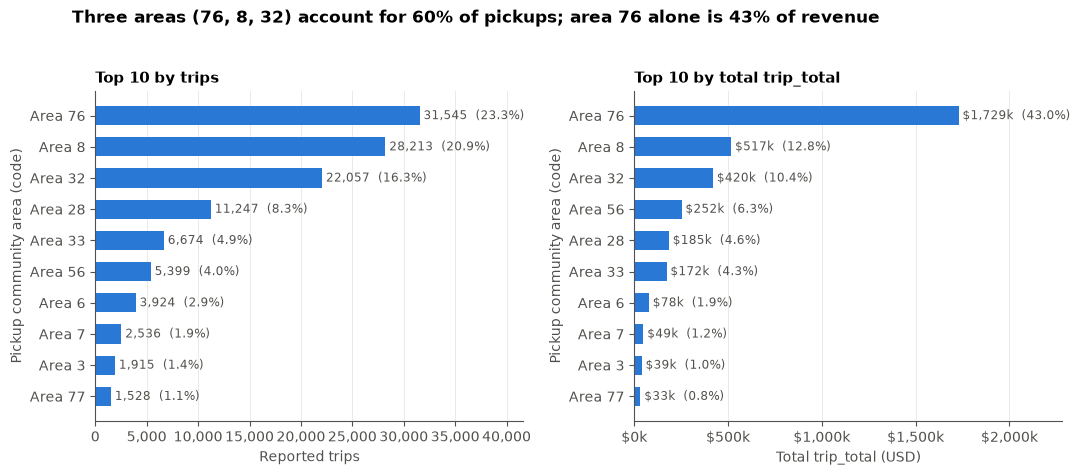

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, tbl, col, share, title, fmt, xlabel in [
    (axes[0], top_n, "trips", "trip_share_%", "Top 10 by trips", lambda v: f"{v:,.0f}", "Reported trips"),
    (axes[1], top_r, "revenue", "revenue_share_%", "Top 10 by total trip_total", lambda v: f"${v/1000:,.0f}k", "Total trip_total (USD)"),
]:
    t = tbl.iloc[::-1]
    ax.barh([f"Area {a}" for a in t.index], t[col], color=BLUE, height=0.62)
    for i, (v, s) in enumerate(zip(t[col], t[share])):
        ax.text(v + t[col].max() * 0.012, i, f"{fmt(v)}  ({s:.1f}%)", va="center", fontsize=8.5, color="#52514e")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, t[col].max() * 1.32)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _, f=fmt: f(v)))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Pickup community area (code)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Three areas (76, 8, 32) account for 60% of pickups; area 76 alone is 43% of revenue", x=0.07, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIG_DIR / "03_top_pickup_areas.png", dpi=150, bbox_inches="tight")
plt.show()